# Experiment 1: Raw counts versus TF-IDF

Compare **raw term counts + cosine similarity** against **TF-IDF + cosine similarity** on 250 BBC news articles (first 50 filenames in each of five categories).

Each article is used as a query once, its own result is excluded, and another article is relevant when it has the same BBC category. Each query therefore has 249 candidates and 49 relevant documents. Report **P@10**, averaged over all 250 queries.

This is a **category-based document retrieval benchmark**, matching `03_dimensionality_reduction.ipynb`. It differs from the supplied starter's 12 short text queries, whose relevance needs human judgements. Category matches are a proxy for topical similarity, not proof that an article answers a specific information need. This notebook does not compute metrics for those 12 queries.

Run all cells in order. Install packages with `python -m pip install -r requirements.txt` from the repository root, then select that Python environment as the notebook kernel. In Colab, upload this notebook and run `%pip install numpy scipy pandas scikit-learn matplotlib` if needed. The data cell downloads the raw archive only when local raw files are missing.

## 1. Configuration and packages
Paths work when the kernel starts in the repository root or in `src/`. For standalone Colab use, outputs are saved under the current working directory. Settings are fixed before inspecting results.

In [1]:
from pathlib import Path
import hashlib
import json
import os
import platform
import urllib.request
import zipfile

# Keep Matplotlib's cache in a writable temporary directory.
import tempfile
os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "cs103-matplotlib"))

import numpy as np
import pandas as pd
import scipy
import sklearn
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.feature_extraction.text import CountVectorizer, TfidfTransformer
from sklearn.metrics.pairwise import cosine_similarity

cwd = Path.cwd().resolve()
ROOT = cwd.parent if cwd.name == "src" else cwd
DATA_DIR = ROOT / "data" / "bbc"
RESULTS_DIR = ROOT / "results"
CATEGORIES = ["business", "entertainment", "politics", "sport", "tech"]
N_PER_CAT = 50
TOP_K = 10
SETTINGS = dict(lowercase=True, stop_words="english", token_pattern=r"[a-zA-Z]{2,}", min_df=2)

print("Project:", ROOT)
print("Preprocessing:", SETTINGS)
print("Python:", platform.python_version(), "| scikit-learn:", sklearn.__version__)

Project: /Users/jolinluk/Downloads/CS103 LINEAR ALGEBRA/CS103-proj
Preprocessing: {'lowercase': True, 'stop_words': 'english', 'token_pattern': '[a-zA-Z]{2,}', 'min_df': 2}
Python: 3.13.5 | scikit-learn: 1.7.2


## 2. Load the raw BBC articles

Use the original **BBC raw text** corpus, not BBCSport or the preprocessed matrix. Source: [Derek Greene's BBC dataset](https://derekgreene.com/bbc/), with the [author's repository](https://github.com/derekgreene/bbc-datasets) as a download fallback.

Place extracted files at `data/bbc/business/001.txt`, etc., or place `bbc-fulltext.zip` in `data/`. If neither is available, the next cell downloads a checksum-verified archive. Files are selected by sorted filename, first 50 per category. This is a deterministic balanced sample, not a random sample.

Index the **whole file, including its headline**, decoded as Latin-1, to match Experiment 3. Categories and filenames are metadata and are never appended to the indexed text. This differs from the starter's body-only indexing. Original duplicate articles are retained; they can make retrieval easier. Original article copyright belongs to the BBC; the source describes non-commercial/research use. Raw articles are kept locally and excluded from Git.

In [2]:
SOURCE_URLS = [
    "https://derekgreene.com/datasets/bbc-fulltext.zip",
    "https://raw.githubusercontent.com/derekgreene/bbc-datasets/main/raw/bbc-fulltext.zip",
]
ARCHIVE_SHA256 = "a351031a62325b3d7ff13146eeb035c22feca8290913b5183d1ff3be35109495"


def article_files(category):
    return sorted(p for p in (DATA_DIR / category).glob("*.txt") if p.stem.isdigit())


if not all(len(article_files(cat)) >= N_PER_CAT for cat in CATEGORIES):
    archive_path = ROOT / "data" / "bbc-fulltext.zip"
    archive_path.parent.mkdir(parents=True, exist_ok=True)
    if not archive_path.exists():
        failures = []
        for url in SOURCE_URLS:
            try:
                request = urllib.request.Request(url, headers={"User-Agent": "CS103-Retrieval/1.0"})
                with urllib.request.urlopen(request, timeout=45) as response:
                    payload = response.read(20_000_001)
                if hashlib.sha256(payload).hexdigest() != ARCHIVE_SHA256:
                    raise ValueError("Unexpected archive checksum; refusing to use it.")
                archive_path.write_bytes(payload)
                break
            except (OSError, ValueError) as exc:
                failures.append(f"{url}: {exc}")
        else:
            raise RuntimeError("Download failed. Place the raw archive in data/bbc-fulltext.zip.\n" + "\n".join(failures))
    if hashlib.sha256(archive_path.read_bytes()).hexdigest() != ARCHIVE_SHA256:
        raise ValueError("The local archive does not match the expected SHA-256.")
    # Copy only expected article paths; never extract arbitrary ZIP paths.
    with zipfile.ZipFile(archive_path) as archive:
        for name in archive.namelist():
            parts = Path(name).parts
            if (len(parts) == 3 and parts[0] == "bbc" and parts[1] in CATEGORIES
                    and Path(parts[2]).suffix == ".txt" and Path(parts[2]).stem.isdigit()):
                destination = DATA_DIR / parts[1] / parts[2]
                destination.parent.mkdir(parents=True, exist_ok=True)
                if not destination.exists():
                    destination.write_bytes(archive.read(name))

texts, labels, doc_ids, manifest_rows = [], [], [], []
for category in CATEGORIES:
    files = article_files(category)
    if len(files) < N_PER_CAT:
        raise ValueError(f"{category}: expected at least {N_PER_CAT} raw articles, found {len(files)}")
    for path in files[:N_PER_CAT]:
        raw = path.read_bytes()
        text = raw.decode("latin-1").strip()
        if not text:
            raise ValueError(f"Empty article: {path}")
        doc_id = f"{category}/{path.name}"
        texts.append(text)
        labels.append(category)
        doc_ids.append(doc_id)
        manifest_rows.append({
            "document_id": doc_id, "category": category,
            "sha256": hashlib.sha256(raw).hexdigest(), "title": text.splitlines()[0],
        })
labels = np.asarray(labels)
manifest = pd.DataFrame(manifest_rows)
assert len(set(doc_ids)) == len(doc_ids)
assert len(texts) == len(CATEGORIES) * N_PER_CAT
print(f"Loaded {len(texts)} documents.")
display(manifest.groupby("category", sort=False).size().rename("documents").to_frame())
print("Extra exact duplicate files retained:", manifest["sha256"].duplicated().sum())

Loaded 250 documents.


,documents
category,
business,50
entertainment,50
politics,50
sport,50
tech,50


Extra exact duplicate files retained: 2


## 3. Build comparable vectors

Use English stop-word removal, alphabetic tokens of at least two letters, and `min_df=2` for both methods, matching Experiment 3. No stemming is applied. Fit the vocabulary once, then transform the same count matrix with IDF so that only term weighting changes.

$$\operatorname{idf}(t)=\ln\left(\frac{1+N}{1+\operatorname{df}(t)}\right)+1,\qquad
\operatorname{tfidf}(t,d)=\operatorname{count}(t,d)\operatorname{idf}(t).$$

`norm=None` exposes the unnormalised TF-IDF weights; cosine similarity normalises both methods during comparison. This gives the same cosine scores as Experiment 3's default L2-normalised `TfidfVectorizer`. All 250 documents form the searchable corpus, so vocabulary and IDF are fitted on all 250. This is a fixed-corpus retrieval experiment, not a held-out classification experiment.

In [3]:
counter = CountVectorizer(**SETTINGS)
X_count = counter.fit_transform(texts)
idf_model = TfidfTransformer(norm=None, use_idf=True, smooth_idf=True, sublinear_tf=False)
X_tfidf = idf_model.fit_transform(X_count)
assert X_count.shape == X_tfidf.shape
if np.any(np.asarray(X_count.sum(axis=1)).ravel() == 0):
    raise ValueError("A document has no usable tokens after preprocessing.")

print("Raw counts:", X_count.shape)
print("TF-IDF:   ", X_tfidf.shape)
print("Rows = documents; columns = shared vocabulary terms.")

Raw counts: (250, 4400)
TF-IDF:    (250, 4400)
Rows = documents; columns = shared vocabulary terms.


## 4. Evaluate P@10

For each query, rank all other articles by decreasing cosine similarity. Exclude the query itself before computing metrics. Tied scores use input order, which is category then filename ascending; even zero-score candidates remain in the full ranking. This is a disclosed convention, and ties can affect metrics.

- **P@10**: number of relevant articles among the first 10 results divided by 10.

If a query has no relevant candidate, its P@10 is zero and the query remains in the average. For a collection with fewer than 10 candidates, missing positions earn zero credit in P@10. This does not affect the 250-article experiment. Cosine similarity is a ranking score, not an evaluation metric.

In [4]:
def evaluate(vectors, labels, k=10, return_details=False):
    """Same-category, all-document retrieval; exclude self and resolve ties stably."""
    labels = np.asarray(labels)
    n = vectors.shape[0]
    if labels.ndim != 1 or len(labels) != n or n < 2:
        raise ValueError("Need at least two vectors and one category label per vector.")
    if not isinstance(k, (int, np.integer)) or k < 1:
        raise ValueError("k must be a positive integer.")
    sim = cosine_similarity(vectors)
    if not np.isfinite(sim).all():
        raise ValueError("Cosine scores must be finite.")
    np.fill_diagonal(sim, -np.inf)
    # Stable sorting breaks ties by the original (sorted document ID) order.
    order = np.argsort(-sim, axis=1, kind="stable")[:, :n - 1]
    assert not np.any(order == np.arange(n)[:, None])
    relevant = labels[order] == labels[:, None]

    precision_k = relevant[:, :k].sum(axis=1) / k
    total_relevant = (labels[:, None] == labels[None, :]).sum(axis=1) - 1
    metrics = {f"P@{k}": float(precision_k.mean())}
    if return_details:
        per_query = pd.DataFrame({f"P@{k}": precision_k,
                                  "relevant_candidates": total_relevant})
        return metrics, per_query, order, sim
    return metrics


# Hand-check: tied scores use input order. Top-2 precisions are
# [1/2, 1/2, 0, 0], so the mean P@2 is 1/4.
check = evaluate(np.eye(4), ["a", "a", "b", "b"], k=2)
np.testing.assert_allclose(check["P@2"], 0.25)
no_positives = evaluate(np.eye(3), ["a", "b", "c"])
np.testing.assert_allclose(no_positives["P@10"], 0)
print("P@10 checks passed: self-exclusion, ties and no-positive queries.")

P@10 checks passed: self-exclusion, ties and no-positive queries.


## 5. Run the comparison
Both methods use the same documents, labels, vocabulary, query set, cosine similarity, self-exclusion and tie rule. No SVD is applied in Experiment 1.

In [5]:
summary_rows, query_frames, ranking_examples = [], [], []
rankings = {}
for method, vectors in [("raw counts", X_count), ("tf-idf", X_tfidf)]:
    metrics, detail, order, scores = evaluate(vectors, labels, k=TOP_K, return_details=True)
    summary_rows.append({"vectors": method, **metrics})
    detail.insert(0, "document_id", doc_ids)
    detail.insert(1, "category", labels)
    detail.insert(2, "vectors", method)
    query_frames.append(detail)
    rankings[method] = (order, scores)

results = pd.DataFrame(summary_rows)
per_query = pd.concat(query_frames, ignore_index=True)
assert (per_query["relevant_candidates"] == N_PER_CAT - 1).all()
display(results.round(6))
by_category = per_query.groupby(["vectors", "category"], sort=False)[["P@10"]].mean()
by_category = by_category.reset_index()
display(by_category.round(6))

,vectors,P@10
0,raw counts,0.7856
1,tf-idf,0.8224


,vectors,category,P@10
0,raw counts,business,0.718
1,raw counts,entertainment,0.720
2,raw counts,politics,0.850
3,raw counts,sport,0.952
4,raw counts,tech,0.688
5,tf-idf,business,0.776
6,tf-idf,entertainment,0.798
7,tf-idf,politics,0.806
8,tf-idf,sport,0.962
9,tf-idf,tech,0.770


## 6. Inspect a query and plot the results
Choose a query ID to inspect its first 10 neighbours. A category match is marked relevant using the same rule as evaluation.

Query: business/001.txt | Ad sales boost Time Warner profit


,query_id,vectors,rank,document_id,title,cosine,relevant
0,business/001.txt,raw counts,1,business/004.txt,High fuel prices hit BA's profits,0.335796,True
1,business/001.txt,raw counts,2,business/038.txt,Deutsche Telekom sees mobile gain,0.326735,True
2,business/001.txt,raw counts,3,business/035.txt,Ad firm WPP's profits surge 15%,0.323479,True
3,business/001.txt,raw counts,4,business/050.txt,Bad weather hits Nestle sales,0.312408,True
4,business/001.txt,raw counts,5,business/040.txt,Umbro profits lifted by Euro 2004,0.301994,True
5,business/001.txt,raw counts,6,business/011.txt,Ask Jeeves tips online ad revival,0.287620,True
6,business/001.txt,raw counts,7,business/013.txt,Peugeot deal boosts Mitsubishi,0.231646,True
7,business/001.txt,raw counts,8,entertainment/046.txt,Howl helps boost Japan's cinemas,0.229382,False
8,business/001.txt,raw counts,9,business/017.txt,Parmalat boasts doubled profits,0.223700,True
9,business/001.txt,raw counts,10,business/027.txt,"Steel firm 'to cut' 45,000 jobs",0.216713,True


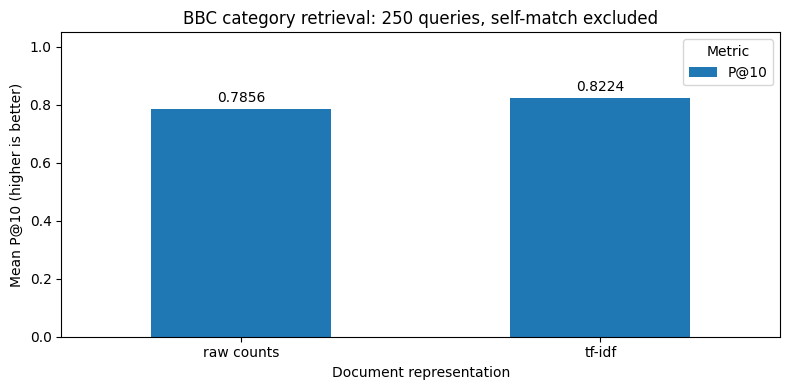

In [6]:
ranking_examples = []
EXAMPLE_QUERY_ID = "business/001.txt"
query_index = doc_ids.index(EXAMPLE_QUERY_ID)
print("Query:", EXAMPLE_QUERY_ID, "|", manifest.loc[query_index, "title"])
for method, (order, scores) in rankings.items():
    for rank, idx in enumerate(order[query_index, :TOP_K], start=1):
        ranking_examples.append({
            "query_id": EXAMPLE_QUERY_ID, "vectors": method, "rank": rank,
            "document_id": doc_ids[idx], "title": manifest.loc[idx, "title"],
            "cosine": float(scores[query_index, idx]), "relevant": bool(labels[idx] == labels[query_index]),
        })
example_results = pd.DataFrame(ranking_examples)
display(example_results)

fig, ax = plt.subplots(figsize=(8, 4))
results.set_index("vectors")[["P@10"]].plot.bar(ax=ax, rot=0)
ax.set_ylim(0, 1.05)
ax.set_xlabel("Document representation")
ax.set_ylabel("Mean P@10 (higher is better)")
ax.set_title("BBC category retrieval: 250 queries, self-match excluded")
ax.legend(title="Metric")
for container in ax.containers:
    ax.bar_label(container, fmt="%.4f", padding=3)
fig.tight_layout()
plt.show()

## 7. Save reproducible results
Save the summary, per-query metrics, category means, example rankings, plot and source-file manifest. Metadata records package versions, preprocessing and the sample fingerprint. These files contain no full article bodies. Keep the executed notebook and results in Git along with the small setup files; the dataset and caches remain local.

In [7]:
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
results.to_csv(RESULTS_DIR / "exp1_results.csv", index=False)
per_query.to_csv(RESULTS_DIR / "exp1_per_query.csv", index=False)
by_category.to_csv(RESULTS_DIR / "exp1_by_category.csv", index=False)
example_results.to_csv(RESULTS_DIR / "exp1_example_rankings.csv", index=False)
manifest.to_csv(RESULTS_DIR / "exp1_manifest.csv", index=False)
fig.savefig(RESULTS_DIR / "exp1_plot.png", dpi=160, bbox_inches="tight")

sample_identity = "\n".join(f"{r['document_id']}:{r['sha256']}" for r in manifest_rows)
metadata = {
    "experiment": "raw counts versus TF-IDF with cosine similarity",
    "source_page": "https://derekgreene.com/bbc/",
    "document_count": len(texts), "vocabulary_size": X_count.shape[1],
    "selection": f"first {N_PER_CAT} numeric .txt filenames per category, sorted ascending",
    "categories": CATEGORIES, "index_fields": "full raw file including headline",
    "decoding": "latin-1", "preprocessing": SETTINGS,
    "tfidf": {"smooth_idf": True, "sublinear_tf": False, "norm": None},
    "evaluation": {"queries": "all documents", "relevance": "same category", "exclude_self": True,
                   "k": TOP_K, "metric": "P@10",
                   "precision_denominator": TOP_K, "zero_score_candidates": "retained",
                   "ties": "input order: category then filename ascending"},
    "sample_sha256": hashlib.sha256(sample_identity.encode("utf-8")).hexdigest(),
    "versions": {"python": platform.python_version(), "numpy": np.__version__,
                 "scipy": scipy.__version__, "pandas": pd.__version__, "scikit-learn": sklearn.__version__},
    "results": results.to_dict(orient="records"),
}
(RESULTS_DIR / "exp1_metadata.json").write_text(json.dumps(metadata, indent=2) + "\n", encoding="utf-8")
print("Saved Experiment 1 outputs to", RESULTS_DIR)

Saved Experiment 1 outputs to /Users/jolinluk/Downloads/CS103 LINEAR ALGEBRA/CS103-proj/results


## 8. Interpret the measured differences
The next cell describes the values from this run; it does not assume TF-IDF wins. Differences are absolute score differences, not relative percentages.

In [8]:
from IPython.display import Markdown
comparison = results.set_index("vectors")
lines = []
for metric in ["P@10"]:
    raw = comparison.loc["raw counts", metric]
    weighted = comparison.loc["tf-idf", metric]
    delta = weighted - raw
    outcome = "higher" if delta > 1e-12 else "lower" if delta < -1e-12 else "equal"
    lines.append(f"- **{metric}**: raw counts = {raw:.4f}; TF-IDF = {weighted:.4f} "
                 f"(TF-IDF is {outcome}; difference {delta:+.4f}).")
display(Markdown("\n".join(lines)))

- **P@10**: raw counts = 0.7856; TF-IDF = 0.8224 (TF-IDF is higher; difference +0.0368).

TF-IDF reduces the relative influence of terms appearing in many documents. Whether this improves retrieval depends on the observed rankings. English stop words were already removed from **both** representations, so this experiment measures the additional effect of IDF after that preprocessing.

P@10 measures the relevance of the first page of results. A score of 0.8 means that, on average, 8 of the first 10 retrieved articles have the same category as the query article.

Limits: categories are broad relevance proxies; the first-50 sample is not random; retained duplicates can inflate quality; and no significance test is performed. Conclusions apply to this fixed collection and setup. If Experiment 3 changes its text fields, preprocessing, sample or relevance definition, rerun Experiment 1 with those same settings before comparing it with SVD results.

References: D. Greene and P. Cunningham, *Practical Solutions to the Problem of Diagonal Dominance in Kernel Document Clustering*, ICML 2006 ([paper](https://derekgreene.com/papers/greene06icml.pdf)); [TF-IDF transformation](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfTransformer.html); [cosine similarity](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.pairwise.cosine_similarity.html).